# Multi-Armed Bandit

In [1]:
import numpy as np
import matplotlib.pyplot as plt


np.random.seed(42)

def style_graph(ax, title, xlabel, ylabel=None):

    # Dark graph background
    ax.set_facecolor("#202124")

    # Title and axis labels
    ax.set_title(title,color="white",fontsize=15)

    ax.set_xlabel(xlabel,color="white",fontsize=12)

    if ylabel is not None:
        ax.set_ylabel(ylabel,color="white",fontsize=12)

    # Tick colors
    ax.tick_params(axis="both",colors="white")

    # White graph borders
    for spine in ax.spines.values():
        spine.set_color("white")

    # Grid styling
    ax.grid(True,alpha=0.25)


def style_legend(legend):

    if legend is not None:

        # Dark legend background
        legend.get_frame().set_facecolor("#202124")
        legend.get_frame().set_edgecolor("white")
        legend.get_frame().set_alpha(0.9)

        # White legend text
        for text in legend.get_texts():
            text.set_color("white")

In [2]:
# 1. Problem Setup

# Number of advertisements (arms)
num_ads = 10

num_trials = 1000

true_probabilities = np.array([
    0.05, 0.10, 0.08, 0.15, 0.12,
    0.20, 0.18, 0.25, 0.22, 0.30
])

# Best possible advertisement
best_ad = np.argmax(true_probabilities)
best_probability = np.max(true_probabilities)

print("Actual best advertisement: Ad", best_ad + 1)
print("Best click probability:", best_probability)

Actual best advertisement: Ad 10
Best click probability: 0.3


In [3]:
# 2. Epsilon Schedules

def standard_epsilon(t, total_trials,epsilon_start=0.1, epsilon_end=0.1):
    return epsilon_start


def linear_decay(t, total_trials,epsilon_start=1.0,epsilon_end=0.01):
    epsilon = epsilon_start - ((epsilon_start - epsilon_end) / total_trials) * t
    return max(epsilon_end, epsilon)


def exponential_decay(t, total_trials,epsilon_start=1.0,epsilon_end=0.01):
    decay_rate = 5.0 / total_trials
    epsilon = epsilon_end + (epsilon_start - epsilon_end) * np.exp(-decay_rate * t)
    return max(epsilon_end, epsilon)


def step_decay(t, total_trials,epsilon_start=1.0,epsilon_end=0.01):
    drop = 0.5
    step_size = 100
    epsilon = epsilon_start * (drop ** (t // step_size))
    return max(epsilon_end, epsilon)


def inverse_time_decay(t, total_trials,epsilon_start=1.0,epsilon_end=0.01):
    decay_rate = 0.01
    epsilon = epsilon_start / (1 + decay_rate * t)
    return max(epsilon_end, epsilon)

In [4]:
# 3. Epsilon-Greedy Algorithm

def run_epsilon_greedy(epsilon_function):

    # Estimated reward Q(A)
    estimated_values = np.zeros(num_ads)

    # N(A): Number of times each advertisement was selected
    selection_counts = np.zeros(num_ads, dtype=int)

    # Store results
    selected_ads = []
    rewards = []
    cumulative_rewards = []
    cumulative_regret = []
    epsilon_history = []

    total_reward = 0
    total_regret = 0

    for t in range(num_trials):

        # Calculate epsilon for current trial
        epsilon = epsilon_function(t, num_trials)
        epsilon_history.append(epsilon)

        # Choose Advertisement
        if np.random.random() < epsilon:
            selected_ad = np.random.randint(num_ads)
        else:
            max_value = np.max(estimated_values)
            best_candidates = np.flatnonzero(np.isclose(estimated_values, max_value))
            selected_ad = np.random.choice(best_candidates)

        # Generate Reward
        reward = (np.random.random()< true_probabilities[selected_ad])
        reward = int(reward)

        selection_counts[selected_ad] += 1

        n = selection_counts[selected_ad]

        estimated_values[selected_ad] += (reward - estimated_values[selected_ad]) / n

        instantaneous_regret = (best_probability- true_probabilities[selected_ad])

        total_regret += instantaneous_regret
        total_reward += reward

        # Save results
        selected_ads.append(selected_ad)
        rewards.append(reward)
        cumulative_rewards.append(total_reward)
        cumulative_regret.append(total_regret)

    return {
        "selected_ads": np.array(selected_ads),
        "rewards": np.array(rewards),
        "cumulative_rewards": np.array(cumulative_rewards),
        "cumulative_regret": np.array(cumulative_regret),
        "epsilon_history": np.array(epsilon_history),
        "estimated_values": estimated_values,
        "selection_counts": selection_counts
    }

In [5]:
# 4. Run All Epsilon-Greedy Variants

algorithms = {
    "Standard Epsilon-Greedy": standard_epsilon,
    "Linear Decay": linear_decay,
    "Exponential Decay": exponential_decay,
    "Step Decay": step_decay,
    "Inverse Time Decay": inverse_time_decay
}

results = {}

for name, epsilon_function in algorithms.items():

    results[name] = run_epsilon_greedy(epsilon_function)

In [6]:
# 5. Display Results

print("FINAL RESULTS AFTER", num_trials, "TRIALS")


for name, result in results.items():

    most_selected_ad = np.argmax(result["selection_counts"])

    print("\nAlgorithm:", name)

    print("Selected Best Advertisement:","Ad", most_selected_ad + 1)

    print("Number of times selected:",result["selection_counts"][most_selected_ad])

    print("Total Reward:",np.sum(result["rewards"]))

    print("Final Cumulative Regret:",round(result["cumulative_regret"][-1], 4))

    print("Estimated Advertisement Values:",np.round(result["estimated_values"], 3))

FINAL RESULTS AFTER 1000 TRIALS

Algorithm: Standard Epsilon-Greedy
Selected Best Advertisement: Ad 10
Number of times selected: 859
Total Reward: 292
Final Cumulative Regret: 18.59
Estimated Advertisement Values: [0.    0.182 0.    0.286 0.111 0.227 0.286 0.273 0.182 0.308]

Algorithm: Linear Decay
Selected Best Advertisement: Ad 8
Number of times selected: 362
Total Reward: 212
Final Cumulative Regret: 96.1
Estimated Advertisement Values: [0.054 0.098 0.119 0.202 0.154 0.17  0.222 0.246 0.223 0.293]

Algorithm: Exponential Decay
Selected Best Advertisement: Ad 9
Number of times selected: 462
Total Reward: 239
Final Cumulative Regret: 66.55
Estimated Advertisement Values: [0.129 0.045 0.111 0.048 0.13  0.13  0.222 0.231 0.232 0.303]

Algorithm: Step Decay
Selected Best Advertisement: Ad 10
Number of times selected: 793
Total Reward: 264
Final Cumulative Regret: 30.7
Estimated Advertisement Values: [0.    0.    0.118 0.154 0.174 0.194 0.235 0.143 0.269 0.295]

Algorithm: Inverse Time D

In [7]:
# 6. Advertisement Selection Counts

print("ADVERTISEMENT SELECTION COUNTS")

for name, result in results.items():
    print("\n", name)
    for ad in range(num_ads):
        print("Ad", ad + 1,":",result["selection_counts"][ad],"times")

ADVERTISEMENT SELECTION COUNTS

 Standard Epsilon-Greedy
Ad 1 : 13 times
Ad 2 : 11 times
Ad 3 : 10 times
Ad 4 : 14 times
Ad 5 : 9 times
Ad 6 : 44 times
Ad 7 : 7 times
Ad 8 : 22 times
Ad 9 : 11 times
Ad 10 : 859 times

 Linear Decay
Ad 1 : 56 times
Ad 2 : 41 times
Ad 3 : 59 times
Ad 4 : 84 times
Ad 5 : 52 times
Ad 6 : 47 times
Ad 7 : 72 times
Ad 8 : 362 times
Ad 9 : 94 times
Ad 10 : 133 times

 Exponential Decay
Ad 1 : 31 times
Ad 2 : 22 times
Ad 3 : 18 times
Ad 4 : 21 times
Ad 5 : 23 times
Ad 6 : 23 times
Ad 7 : 27 times
Ad 8 : 13 times
Ad 9 : 462 times
Ad 10 : 360 times

 Step Decay
Ad 1 : 29 times
Ad 2 : 17 times
Ad 3 : 17 times
Ad 4 : 26 times
Ad 5 : 23 times
Ad 6 : 31 times
Ad 7 : 17 times
Ad 8 : 21 times
Ad 9 : 26 times
Ad 10 : 793 times

 Inverse Time Decay
Ad 1 : 23 times
Ad 2 : 18 times
Ad 3 : 20 times
Ad 4 : 26 times
Ad 5 : 22 times
Ad 6 : 33 times
Ad 7 : 20 times
Ad 8 : 175 times
Ad 9 : 50 times
Ad 10 : 613 times


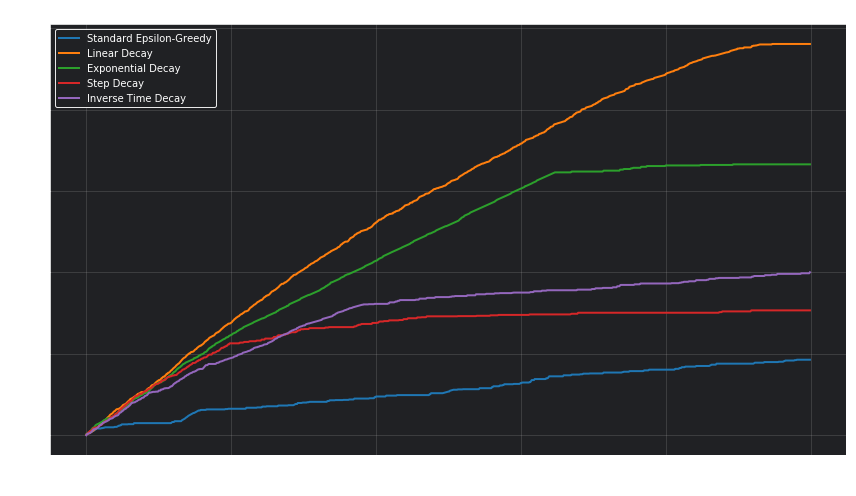

In [8]:
# 7. Plot Cumulative Regret

plt.figure(figsize=(12, 7))

for name, result in results.items():

    plt.plot(result["cumulative_regret"],label=name,linewidth=2)

ax = plt.gca()

style_graph(ax,"Cumulative Regret of Epsilon-Greedy Variants","Trial","Cumulative Regret")

legend = plt.legend(loc="upper left",frameon=True,fontsize=10)

style_legend(legend)

plt.tight_layout()
plt.show()

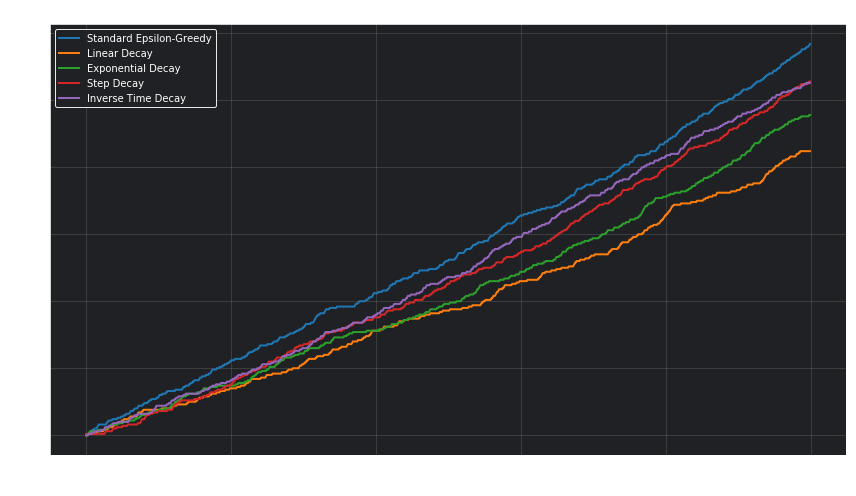

In [9]:
# 8. Plot Cumulative Reward

plt.figure(figsize=(12, 7))

for name, result in results.items():

    plt.plot(result["cumulative_rewards"],label=name,linewidth=2)

ax = plt.gca()

style_graph(ax,"Cumulative Reward of Epsilon-Greedy Variants","Trial","Cumulative Reward")

legend = plt.legend(loc="upper left",frameon=True,fontsize=10)

style_legend(legend)

plt.tight_layout()
plt.show()

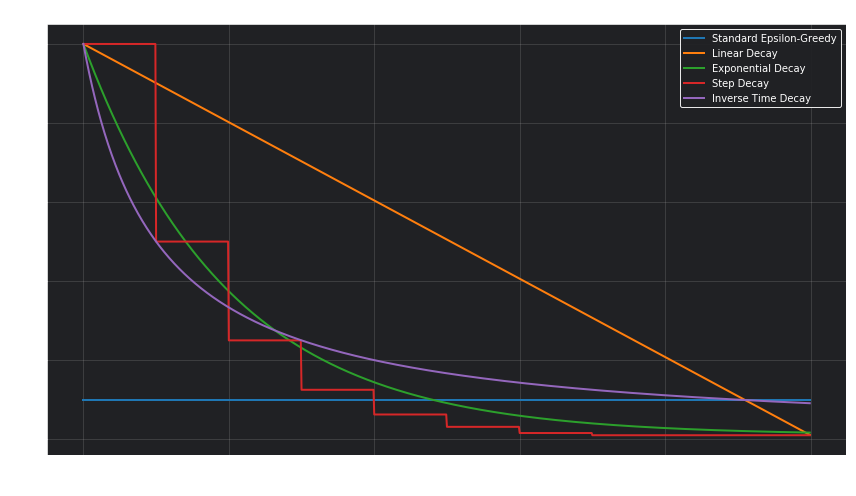

In [10]:
# 9. Plot Epsilon Decay

plt.figure(figsize=(12, 7))

for name, result in results.items():

    plt.plot(result["epsilon_history"],label=name,linewidth=2)

ax = plt.gca()

style_graph(ax,"Exploration Rate for Different Epsilon-Greedy Variants","Trial","Epsilon")

legend = plt.legend(loc="upper right",frameon=True,fontsize=10)

style_legend(legend)

plt.tight_layout()
plt.show()

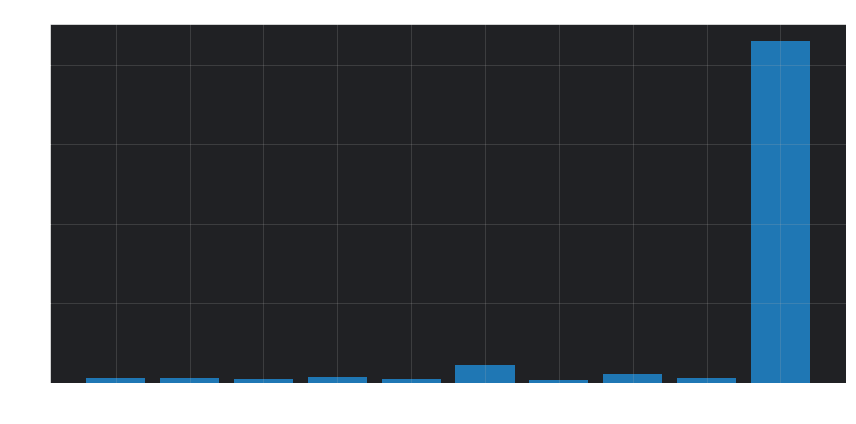

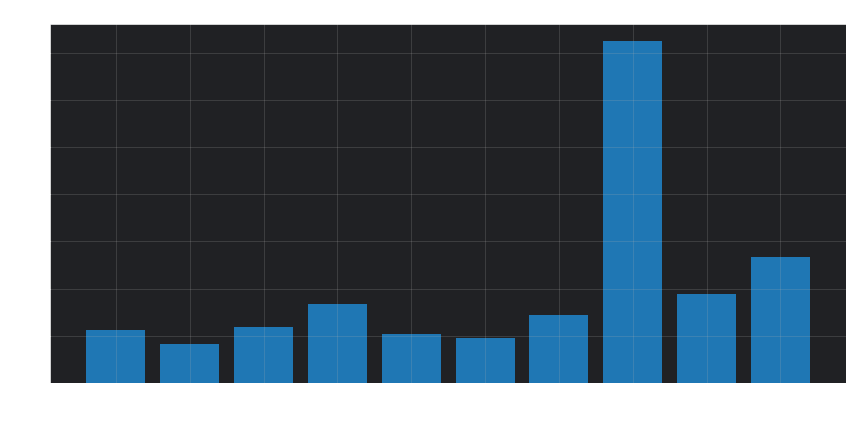

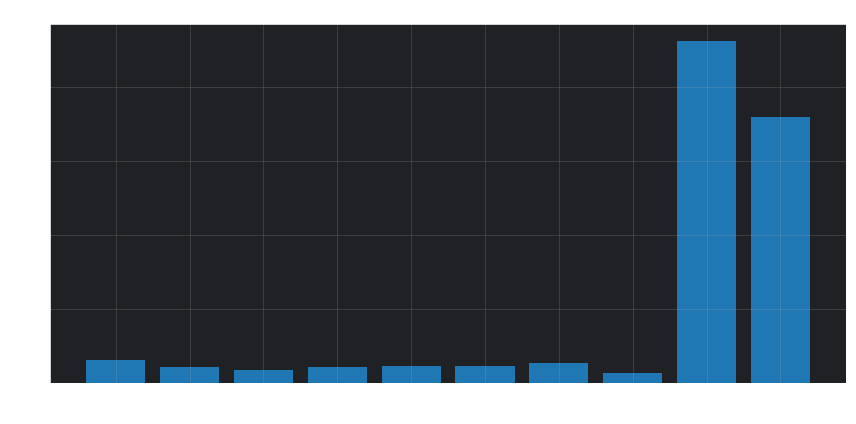

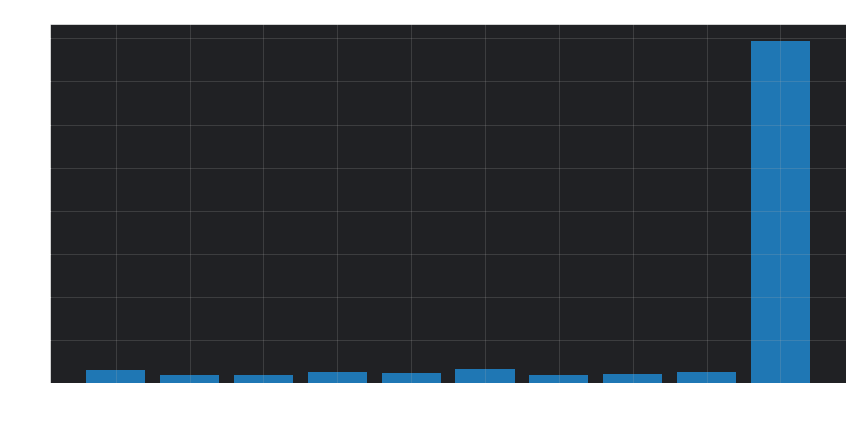

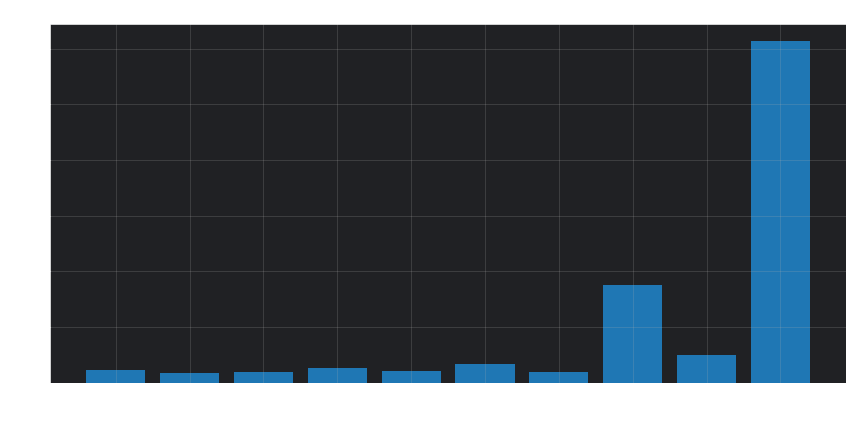

In [11]:
# 10. Plot Advertisement Selection Counts

x = np.arange(1, num_ads + 1)

for name, result in results.items():

    plt.figure(figsize=(12, 6))

    plt.bar(x,result["selection_counts"])

    ax = plt.gca()

    style_graph(ax,"Advertisement Selection - " + name,"Advertisement","Number of Selections")

    plt.xticks(x,["Ad " + str(i) for i in x],color="white")

    plt.tight_layout()
    plt.show()